### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [47]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_and_preprocess_data,
    load_and_preprocess_forecast_data,
)
from data_processing.utils import load_scaler_params, load_checkpoint
from models.model import model_mw_gamma

In [48]:
# TODO
# DONE load evaluation input
# fix column names
# DONE calculate capacity factor
# DONE load model from checkpoint
# DONE (select bidding zone)
# DONE evaluate model for (all) bidding zone
# multiply with available capacity to get absolute generated power
# DONE save median, q025 and q975 in a CSV
# DONE verify format with verify_example.py
# check how good forecast was afterwards (in competition one day later)

In [68]:
bid_zone = "ELSPOT NO1"
date = "2025-09-20"
evaluation_dates = [
    "2025-09-22",
    "2025-09-23",
    "2025-09-24",
    "2025-09-25",
    "2025-09-26",
    "2025-09-29",
    "2025-09-30",
    "2025-10-01",
    "2025-10-02",
    "2025-10-03",
]

In [50]:
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

### Load params and evaluation data


In [51]:
# Load scaler params (same for all models in this bid zone)
scaler_data = load_scaler_params(bid_zone=bid_zone, dir_path="../checkpoints")

# Load evaluation data using training scaler params
eval_nowcast = load_evaluation_data(
    date=date,
    scaler_params=scaler_data["scaler_params"],
    site_scaler_params=scaler_data["site_scaler_params"],
    bid_zone=bid_zone,
    dataset="nowcast",
)
eval_forecast = load_evaluation_data(
    date=date,
    scaler_params=scaler_data["scaler_params"],
    site_scaler_params=scaler_data["site_scaler_params"],
    bid_zone=bid_zone,
    dataset="forecast",
    ensemble_member=0,
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Loaded scaler parameters for ELSPOT NO1
  Saved at: 2025-11-24 14:38:41
  Split time: 2025-01-01 00:00:00+01:00
Filtered to target day: 2025-09-20
  Weather data: 1464 timestamps
  Windpower data: 24 timestamps
Loading evaluation data for 2025-09-20 in zone ELSPOT NO1
  Filtered weather shape: (144, 9) (original: (1464, 9))


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Evaluation data shape: X=(24, 6, 6), Y_gen=(24,)
Index(['sid', 'time_ref', 'time', 'lt', 'ws10m_0', 'ws10m_1', 'ws10m_2',
       'ws10m_3', 'ws10m_4', 'ws10m_5', 'ws10m_6', 'ws10m_7', 'ws10m_8',
       'ws10m_9', 'ws10m_10', 'ws10m_11', 'ws10m_12', 'ws10m_13', 'ws10m_14',
       'wd10m_0', 'wd10m_1', 'wd10m_2', 'wd10m_3', 'wd10m_4', 'wd10m_5',
       'wd10m_6', 'wd10m_7', 'wd10m_8', 'wd10m_9', 'wd10m_10', 'wd10m_11',
       'wd10m_12', 'wd10m_13', 'wd10m_14', 't2m_0', 't2m_1', 't2m_2', 't2m_3',
       't2m_4', 't2m_5', 't2m_6', 't2m_7', 't2m_8', 't2m_9', 't2m_10',
       't2m_11', 't2m_12', 't2m_13', 't2m_14', 'rh2m_0', 'rh2m_1', 'rh2m_2',
       'rh2m_3', 'rh2m_4', 'rh2m_5', 'rh2m_6', 'rh2m_7', 'rh2m_8', 'rh2m_9',
       'rh2m_10', 'rh2m_11', 'rh2m_12', 'rh2m_13', 'rh2m_14', 'mslp_0',
       'mslp_1', 'mslp_2', 'mslp_3', 'mslp_4', 'mslp_5', 'mslp_6', 'mslp_7',
       'mslp_8', 'mslp_9', 'mslp_10', 'mslp_11', 'mslp_12', 'mslp_13',
       'mslp_14', 'g10m_0', 'g10m_1', 'g10m_2', 'g10m_3

QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Evaluation data shape: X=(24, 6, 6), Y_gen=(24,)


In [52]:
# Load trained model checkpoint, bidding zone specific!
checkpoint = load_checkpoint(file_name="model_mw_gamma_2025-11-13_10-56-50_gen")

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


### Run inference


In [53]:
eval_data = eval_forecast

In [54]:
_, rng_key_predict = random.split(checkpoint["rng_key"])

predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
    rng_key_predict, eval_data["X_eval"]
)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

median = np.percentile(preds, 50, axis=0)
q025 = np.percentile(preds, 2.5, axis=0)
q975 = np.percentile(preds, 97.5, axis=0)
hdi = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

### Save predictions as CSV


In [55]:
forecast = pd.DataFrame(
    index=eval_data["index"],
    columns=bid_zones,
    data=0,
)
forecast_extended = [
    pd.DataFrame(
        index=eval_data["index"],
        columns=["median", "hdi_lower", "hdi_upper"],
        data=0,
    )
    for i in range(len(bid_zones))
]

In [56]:
for i, bz in enumerate(bid_zones):

    # Load bid zone specific trained model checkpoint
    checkpoint = load_checkpoint(
        file_name="model_mw_gamma_2025-11-13_10-56-50_gen"
    )  # TODO make it bid zone specific

    # Run inference
    _, rng_key_predict = random.split(checkpoint["rng_key"])

    predictive = Predictive(model_mw_gamma, checkpoint["samples"])(
        rng_key_predict, eval_data["X_eval"]
    )

    preds = predictive["Y"]
    median = np.percentile(preds, 50, axis=0)
    hdis = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)
    hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]

    forecast[bz] = median
    forecast_extended[i][["median", "hdi_lower", "hdi_upper"]] = np.column_stack(
        [median, hdi_lower, hdi_upper]
    )

    break  # TODO no checkpoints for other bid zones so far

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


In [57]:
# Save predictions to CSV
data_folder = f"../data/evaluation/{date}"
file_path = f"{data_folder}/forecast.csv"
if not os.path.exists(data_folder):
    os.makedirs(data_folder)
forecast.to_csv(file_path)

In [58]:
forecast

,ELSPOT_NO1,ELSPOT_NO2,ELSPOT_NO3,ELSPOT_NO4
time,,,,
2025-09-22 00:00:00+02:00,179.509186,0,0,0
2025-09-22 01:00:00+02:00,176.479004,0,0,0
2025-09-22 02:00:00+02:00,179.619019,0,0,0
2025-09-22 03:00:00+02:00,171.478638,0,0,0
2025-09-22 04:00:00+02:00,153.178375,0,0,0
2025-09-22 05:00:00+02:00,143.695206,0,0,0
2025-09-22 06:00:00+02:00,142.806000,0,0,0
2025-09-22 07:00:00+02:00,140.270325,0,0,0
2025-09-22 08:00:00+02:00,149.104828,0,0,0


In [59]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [60]:
i = 0  # [0,1,2,3], choose which bid zone should be plotted
bid_zone = f"ELSPOT_NO{i+1}"

In [61]:
rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))
print("Test RMSE (gen prediction):", rmse)

Test RMSE (gen prediction): 116.39443


In [62]:
inside = (eval_data["Y_eval_gen"] >= forecast_extended[i]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecast_extended[i]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_nowcast["Y_eval_gen"] <= forecast_extended[i]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")


Empirical coverage (0.025–0.975): 0.708
Below median (should be ~0.5): 0.458


### Plot prediction


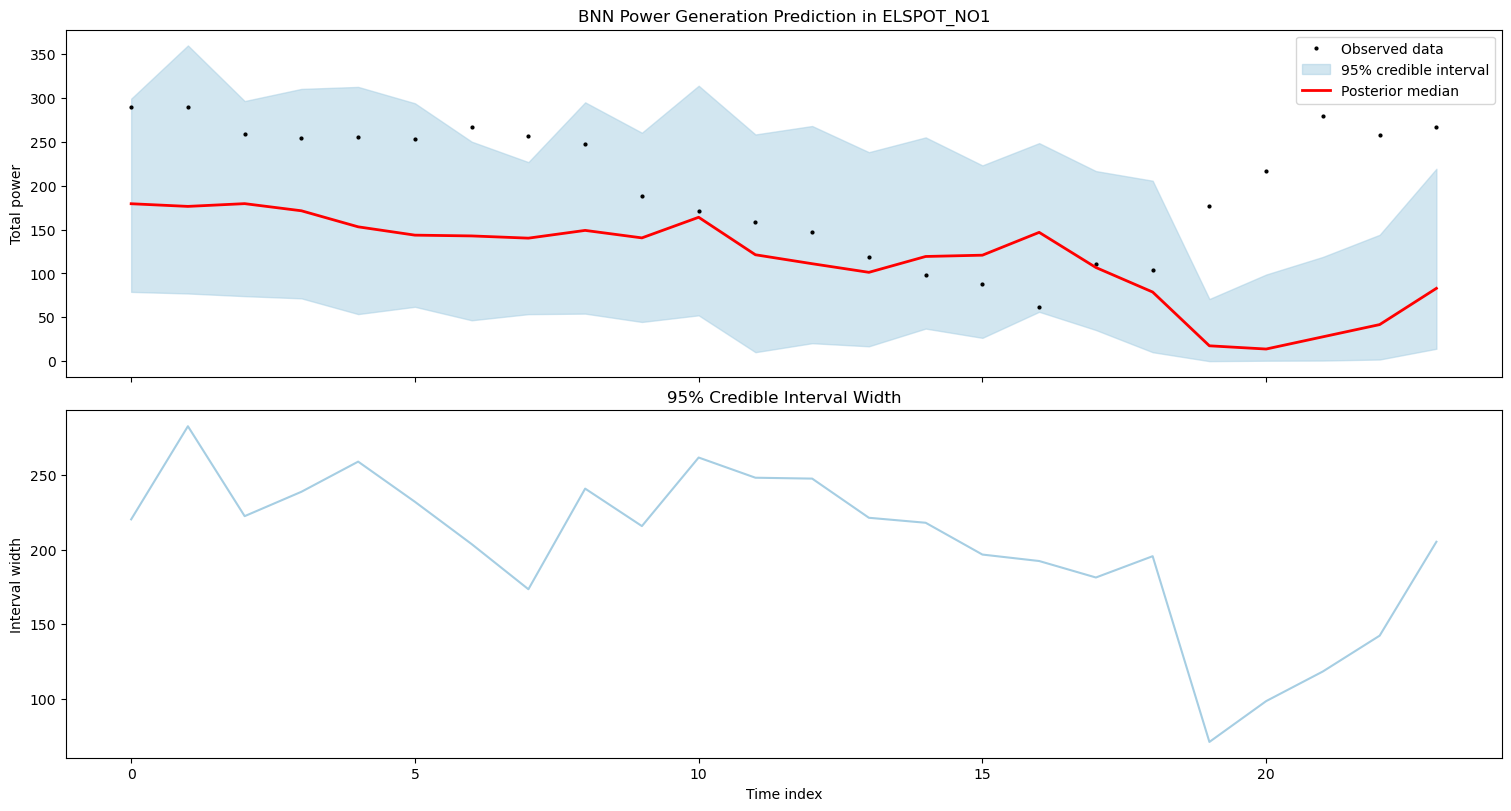

In [63]:
fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    np.arange(24),
    forecast_extended[i]["hdi_lower"].values,
    forecast_extended[i]["hdi_upper"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
)

ax.set(
    ylabel="Total power",
    title=f"BNN Power Generation Prediction in {bid_zone}",
)
ax.legend()


# Compute interval width
width = (
    forecast_extended[i]["hdi_upper"].values - forecast_extended[i]["hdi_lower"].values
)
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()

In [67]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [66]:
# # Now load forecast data using the SAME scaler parameters
# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=scaler_data["scaler_params"],
#     site_scaler_params=scaler_data["site_scaler_params"],
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )